# 10 SFT 数据集构建：从 JSONL 到训练集

这一节把"非结构化原料"变成"能直接喂给训练脚本的 SFT 数据集"。

### SFT 数据的三种常见格式

| 格式 | 长什么样 | 适合 |
| --- | --- | --- |
| **Alpaca** | `{"instruction": …, "input": …, "output": …}` | 单轮指令跟随，最常见 |
| **ShareGPT** | `{"conversations": [{"from": "human", "value": …}, …]}` | 多轮对话 |
| **messages** | `{"messages": [{"role": "system"/"user"/"assistant", "content": …}]}` | OpenAI 风格，多轮 + system |

三种格式字段名不同，但本质是同一个东西：**一段用户输入 + 一段期望输出**。
所以工程上的做法是：**先把所有来源统一成内部 schema，处理完再导出成目标格式**。

```
内部 schema：id | source | system | prompt | response | messages | 元数据
```

### 本节流程

```
读取（容错）→ 展开对话 → 统一 schema → 校验 → 脱敏 → 质量过滤 → 去重 → 划分 → 导出
```

> 环境：`llm_sft`，从 `python/pandas` 目录启动。

In [1]:
import hashlib
import json
import re
import unicodedata
from difflib import SequenceMatcher
from pathlib import Path

import numpy as np
import pandas as pd

pd.set_option("display.unicode.east_asian_width", True)
pd.set_option("display.max_colwidth", 70)

DATA = Path("data")
if not DATA.exists():
    DATA = Path("python/pandas/data")
RAW_SFT = DATA / "raw_sft"
OUT = DATA.parent / "output"
OUT.mkdir(exist_ok=True)

for p in sorted(RAW_SFT.iterdir()):
    print(f"{p.name:20s} {p.stat().st_size:>6,} 字节")

alpaca_raw.jsonl      1,542 字节
chat_logs.jsonl       5,320 字节
faq_qa.json           1,243 字节


## 1. 读取 JSONL：一定要容错

`pd.read_json(..., lines=True)` 有一个坏行就会整份失败，而线上日志**必然**有坏行。
所以自己逐行解析：好的进表，坏的进错误表，最后一起汇报。

In [2]:
def read_jsonl(path: Path) -> tuple[pd.DataFrame, pd.DataFrame]:
    """逐行读 JSONL：返回 (成功记录表, 坏行表)。"""
    records, bad = [], []
    with path.open(encoding="utf-8") as f:
        for lineno, line in enumerate(f, 1):
            line = line.strip()
            if not line:
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as e:
                bad.append({"行号": lineno, "错误": str(e)[:60], "原文": line[:60]})
    return pd.DataFrame(records), pd.DataFrame(bad)


logs, bad_lines = read_jsonl(RAW_SFT / "chat_logs.jsonl")
print("成功:", len(logs), "行 | 坏行:", len(bad_lines))
bad_lines

成功: 14 行 | 坏行: 1


,行号,错误,原文
0,15,"Expecting ',' delimiter: line 1 column 92 (char 91)","{""id"": ""log-015"", ""source"": ""online"", ""messages"": [{""role"":"


## 2. 展开对话：`explode` + `json_normalize`

一条记录里 `messages` 是一个列表，每个元素是 `{"role": ..., "content": ...}`。
想用 pandas 分析，就要先摊平成"一轮一行"：

1. `explode("messages")`：一行炸成多行；
2. `json_normalize`：把字典列展开成 `role` / `content` 两列；
3. 横向拼回去。

In [3]:
# 先体检：messages 的类型是否都是列表？
kind = logs["messages"].map(lambda m: type(m).__name__)
print(kind.value_counts().to_dict())

valid = logs[logs["messages"].map(lambda m: isinstance(m, list))].copy()
broken = logs.drop(valid.index)
print("结构正常:", len(valid), "| 结构异常:", len(broken))
broken[["id", "source", "messages"]]

{'list': 12, 'float': 1, 'str': 1}
结构正常: 12 | 结构异常: 2


,id,source,messages
2,log-003,import,NaN
10,log-011,online,user: 你好\nassistant: 你好


In [4]:
# 把 meta 字典也展平成列（model / tokens / lang）
meta = pd.json_normalize(valid["meta"])
valid = pd.concat([valid.drop(columns="meta").reset_index(drop=True), meta.reset_index(drop=True)], axis=1)

turns = valid.explode("messages").reset_index(drop=True)
turns = pd.concat([turns.drop(columns="messages"), pd.json_normalize(turns["messages"])], axis=1)
turns["turn_idx"] = turns.groupby("id").cumcount()      # 第几轮
print("摊平后:", turns.shape)
turns.head(4)

摊平后: (25, 8)


,id,source,model,tokens,lang,role,content,turn_idx
0,log-001,online,qwen2,88,zh,user,怎么给文档建立向量索引？,0
1,log-001,online,qwen2,88,zh,assistant,先切分文档，再调用 embedding 接口，最后写入向量库。,1
2,log-002,online,qwen2,42,zh,human,支持哪些文档格式？,0
3,log-002,online,qwen2,42,zh,gpt,支持 PDF、Markdown 和 Word。,1


In [5]:
# 角色名要统一：不同来源的写法五花八门
ROLE_MAP = {"human": "user", "gpt": "assistant", "bot": "assistant", "USER": "user", "Assistant": "assistant"}
turns["role_raw"] = turns["role"]
turns["role"] = turns["role"].map(ROLE_MAP).fillna(turns["role"].astype("string"))
turns["content"] = turns["content"].astype("string").str.strip()

print("原始角色取值:", turns["role_raw"].value_counts(dropna=False).to_dict())
print("归一后角色:", turns["role"].value_counts(dropna=False).to_dict())
print("空内容轮数:", (turns["content"].str.len().fillna(0) == 0).sum())

原始角色取值: {'user': 11, 'assistant': 11, 'human': 1, 'gpt': 1, 'system': 1}
归一后角色: {'user': 12, 'assistant': 12, 'system': 1}
空内容轮数: 3


### 摊平后再"折回"对话

分析阶段用"一轮一行"，构建样本时又要"一条对话一行"。
`pivot_table(aggfunc="first")` 可以把 user / assistant 合成同一行的两列，
`groupby(...).agg(list)` 可以把所有轮次收回一个列表。

In [6]:
# 一条对话一行：user 一列、assistant 一列
wide = (
    turns.pivot_table(
        index=["id", "source", "model", "lang"],
        columns="role",
        values="content",
        aggfunc="first",
    )
    .reset_index()
    .rename(columns={"user": "prompt", "assistant": "response"})
    .rename_axis(columns=None)
)

# 对话级信息：轮数、首轮角色、完整消息列表
turns = turns.sort_values(["id", "turn_idx"])
turns["msg"] = [{"role": r, "content": c} for r, c in zip(turns["role"], turns["content"])]
messages = turns.groupby("id")["msg"].agg(list)

conv = wide.assign(
    n_turns=wide["id"].map(turns.groupby("id").size()),
    first_role=wide["id"].map(turns.groupby("id")["role"].first()),
    messages=wide["id"].map(messages),
)
conv[["id", "source", "prompt", "response", "n_turns", "first_role"]]

,id,source,prompt,response,n_turns,first_role
0,log-001,online,怎么给文档建立向量索引？,先切分文档，再调用 embedding 接口，最后写入向量库。,4,user
1,log-002,online,支持哪些文档格式？,支持 PDF、Markdown 和 Word。,2,user
2,log-004,online,计费方式是怎样的？,,2,user
3,log-006,online,帮我总结一下这段长文档的要点。,模型在长上下文场景下的表现取决于训练数据的长度分布，如果训练语料普遍较短，推理时遇到长文档就容易丢失中间信息，因此需要在数据构建阶段...,2,user
4,log-007,enterprise,我的邮箱是 zhang.wei@corp.example.com，手机 13912345678，能帮我登记吗？......,已为你登记，后续通知会发送到 zhang.wei@corp.example.com。,2,user
5,log-008,online,这个功能太赞了！！！👍👍👍 什么时候上线？🎉,预计下个版本上线，具体时间以公告为准 😊,2,user
6,log-009,online,报销流程是什么？,登录 OA 填写报销单，上传发票，提交给直属主管审批，财务复核后 5 个工作日内打款。......,3,system
7,log-010,import,1+1 等于几？,二,2,user
8,log-012,online,明白了。,先切分文档，再做索引。,2,assistant
9,log-013,enterprise,,,2,user


## 3. 第二个来源：Alpaca 格式

来源不同，字段不同，但都能映射到同一套 `id / source / prompt / response`：

- `instruction` + `input` → `prompt`（input 非空时拼在后面，中间空一行）
- `output` → `response`

In [7]:
alpaca_raw, alpaca_bad = read_jsonl(RAW_SFT / "alpaca_raw.jsonl")
print("成功:", len(alpaca_raw), "| 坏行:", len(alpaca_bad))

instruction = alpaca_raw["instruction"].fillna("").astype("string").str.strip()
extra_input = alpaca_raw["input"].fillna("").astype("string").str.strip()
prompt = np.where(extra_input.eq(""), instruction, instruction + "\n\n" + extra_input)
# instruction 为空的样本即使有 input 也不成立，直接置空，交给后面的校验规则拦截
prompt = pd.Series(prompt).str.strip().mask(instruction.eq(""))
has_chinese = prompt.str.contains("[\u4e00-\u9fff]", na=False)   # 直接写字符区间，不要用 r"\u4e00"

alpaca = pd.DataFrame({
    "id": [f"alpaca-{i:02d}" for i in range(1, len(alpaca_raw) + 1)],
    "source": "alpaca",
    "system": pd.NA,
    "prompt": prompt,
    "response": alpaca_raw["output"],
    "model": pd.NA,
    "lang": np.where(has_chinese, "zh", "en"),
    "n_turns": 2,
    "first_role": "user",
})
alpaca["messages"] = [
    [{"role": "user", "content": p}, {"role": "assistant", "content": r}]
    for p, r in zip(alpaca["prompt"], alpaca["response"])
]
alpaca.head(3)

成功: 11 | 坏行: 0


,id,source,system,prompt,response,model,lang,n_turns,first_role,messages
0,alpaca-01,alpaca,<NA>,解释什么是向量数据库,向量数据库用于存储和检索向量化的数据，常见于语义搜索与 RAG 场景。,<NA>,zh,2,user,"[{'role': 'user', 'content': '解释什么是向量数据库'}, {'role': 'assistant', ..."
1,alpaca-02,alpaca,<NA>,解释一下什么是向量数据库,向量数据库用于存储和检索向量化的数据，常见于语义搜索与 RAG 场景。,<NA>,zh,2,user,"[{'role': 'user', 'content': '解释一下什么是向量数据库'}, {'role': 'assistant'..."
2,alpaca-03,alpaca,<NA>,把下面的句子翻译成英文\n\n知识库需要定期更新。,The knowledge base needs regular updates.,<NA>,zh,2,user,"[{'role': 'user', 'content': '把下面的句子翻译成英文 知识库需要定期更新。'}, {'role': ..."


In [8]:
# 两个来源合并：列对齐，缺的列自动变 NaN
COLS = ["id", "source", "system", "prompt", "response", "messages", "model", "lang", "n_turns", "first_role"]
data = pd.concat([conv[COLS], alpaca[COLS]], ignore_index=True)
print("合并后:", data.shape)
data["source"].value_counts()

合并后: (22, 10)


source
alpaca        11
online         8
enterprise     2
import         1
Name: count, dtype: int64

## 4. 校验：把"不合格"写成规则

SFT 数据最常见的五类问题：

| 问题 | 后果 |
| --- | --- |
| prompt / response 为空 | 训练时 loss 全是 padding，浪费算力 |
| response 太短（"嗯""好的"） | 模型学会敷衍 |
| response 太长 | 超出上下文被截断，学不到结尾 |
| 角色顺序错（assistant 在前） | 训练目标错位 |
| 同一来源里重复出现 | 过拟合、验证集泄漏 |

校验不要写成 `if/elif` 一大坨，而是**每条规则一个布尔列**，最后合并成问题清单。

In [9]:
rules = {
    "prompt 为空": data["prompt"].fillna("").astype("string").str.len() < 2,
    "response 为空": data["response"].fillna("").astype("string").str.len() < 2,
    "response 过短(<8字)": data["response"].fillna("").astype("string").str.len() < 8,
    "prompt 过长(>1000字)": data["prompt"].fillna("").astype("string").str.len() > 1000,
    "角色顺序异常": data["first_role"].eq("assistant"),
}
rule_matrix = pd.DataFrame(rules)
print(rule_matrix.sum().to_string())

prompt 为空             2
response 为空           4
response 过短(<8字)     4
prompt 过长(>1000字)    0
角色顺序异常            1


In [10]:
problem_rows = rule_matrix.any(axis=1)
detail = data.loc[problem_rows, ["id", "source", "prompt", "response"]].copy()
detail["问题"] = rule_matrix[problem_rows].apply(lambda r: "、".join(r.index[r.values]), axis=1)
print("问题样本:", len(detail), "/", len(data))
detail

问题样本: 6 / 22


,id,source,prompt,response,问题
2,log-004,online,计费方式是怎样的？,,response 为空、response 过短(<8字)
7,log-010,import,1+1 等于几？,二,response 为空、response 过短(<8字)
8,log-012,online,明白了。,先切分文档，再做索引。,角色顺序异常
9,log-013,enterprise,,,prompt 为空、response 为空、response 过短(<8字)
16,alpaca-06,alpaca,<NA>,这条样本的 instruction 是空的，应当被过滤。,prompt 为空
17,alpaca-07,alpaca,总结下面这段文本\n\n订单已发货，预计 3 天送达。,<NA>,response 为空、response 过短(<8字)


In [11]:
# 记录后再删除（保留 detail 用于人工复核）
data_clean = data[~problem_rows].reset_index(drop=True)
print("校验后剩余:", len(data_clean))

校验后剩余: 16


## 5. 脱敏：训练数据里不该有真实个人信息

邮箱、手机号、身份证号是最常见的三类。注意：

- 脱敏要在**训练前**做，训练后无法补救；
- 脱敏不是删掉整条样本，而是替换成占位符，保留上下文。

In [12]:
EMAIL = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b")
PHONE = re.compile(r"\b1[3-9]\d{9}\b")
ID_CARD = re.compile(r"\b\d{6}(?:19|20)\d{2}(?:0[1-9]|1[0-2])(?:0[1-9]|[12]\d|3[01])\d{3}[\dXx]\b")


def mask_pii(text) -> str:
    text = str(text) if pd.notna(text) else ""
    text = EMAIL.sub("[EMAIL]", text)
    text = PHONE.sub("[手机号]", text)
    return ID_CARD.sub("[身份证号]", text)


before = data_clean[["prompt", "response"]].astype("string")
data_clean["prompt"] = data_clean["prompt"].map(mask_pii)
data_clean["response"] = data_clean["response"].map(mask_pii)

masked = (before["prompt"].fillna("").to_numpy() != data_clean["prompt"].to_numpy()) | (
    before["response"].fillna("").to_numpy() != data_clean["response"].to_numpy()
)
print("命中 PII 并脱敏的样本数:", int(masked.sum()))
data_clean.loc[masked, ["id", "prompt", "response"]]

命中 PII 并脱敏的样本数: 1


,id,prompt,response
3,log-007,我的邮箱是 [EMAIL]，手机 [手机号]，能帮我登记吗？,已为你登记，后续通知会发送到 [EMAIL]。


## 6. 质量指标与过滤

除了"空/短/长"，还有几个信号值得做成指标：

- **重复字符比例**：`max(单字出现次数)/总长度`，能抓出"啊啊啊啊啊"这种废样本；
- **中文占比**：中英混合场景下，占比过低说明可能抓错了内容；
- **估算 token 数**：训练前必须知道长度分布，才能定 `max_length` 和截断策略。

In [13]:
def estimate_tokens(text: str) -> int:
    """粗估 token：中文 1 字≈1 token，英文 1 词≈1.3 token，其余符号≈0.25 token。
    真要精确计数，用 `AutoTokenizer.from_pretrained(模型名)` 再 encode。"""
    text = str(text)
    zh = len(re.findall(r"[\u4e00-\u9fff]", text))
    words = len(re.findall(r"[a-zA-Z]+", text))
    rest = max(len(text) - zh, 0) - sum(len(w) for w in re.findall(r"[a-zA-Z]+", text))
    return int(zh + words * 1.3 + max(rest, 0) * 0.25)


def repeat_ratio(text: str) -> float:
    text = str(text)
    if not text:
        return 1.0
    return max(text.count(ch) for ch in set(text)) / len(text)


data_clean["prompt_len"] = data_clean["prompt"].str.len()
data_clean["response_len"] = data_clean["response"].str.len()
data_clean["zh_ratio"] = data_clean["prompt"].map(
    lambda t: len(re.findall(r"[\u4e00-\u9fff]", t)) / max(len(t), 1)
)
data_clean["repeat_ratio"] = data_clean["response"].map(repeat_ratio).round(3)
data_clean["est_tokens"] = (data_clean["prompt"].map(estimate_tokens) + data_clean["response"].map(estimate_tokens))

data_clean[["prompt_len", "response_len", "zh_ratio", "repeat_ratio", "est_tokens"]].describe().round(2)

,prompt_len,response_len,zh_ratio,repeat_ratio,est_tokens
count,16.00,16.00,16.00,16.00,16.00
mean,14.12,68.56,0.75,0.11,64.00
std,6.45,141.09,0.29,0.06,138.52
min,8.00,10.00,0.00,0.04,12.00
25%,10.00,23.00,0.52,0.06,20.00
50%,12.00,34.00,0.88,0.09,31.00
75%,16.50,36.50,1.00,0.14,40.50
max,30.00,592.00,1.00,0.25,582.00


In [14]:
filter_rules = {
    "重复字符过多": data_clean["repeat_ratio"] > 0.5,
    "response 过长(>2000字)": data_clean["response_len"] > 2000,
    "中英都几乎没有": data_clean["zh_ratio"] < 0.1,
}
report = pd.DataFrame({
    "规则": list(filter_rules),
    "命中数": [int(m.sum()) for m in filter_rules.values()],
    "剩余": [int((~m).sum()) for m in filter_rules.values()],
})

keep = ~pd.DataFrame(filter_rules).any(axis=1)
print("过滤前:", len(data_clean), "→ 过滤后:", int(keep.sum()))
report

过滤前: 16 → 过滤后: 15


,规则,命中数,剩余
0,重复字符过多,0,16
1,response 过长(>2000字),0,16
2,中英都几乎没有,1,15


长度分布（估算 token）:
count     15.0
mean      66.5
std      143.0
min       12.0
25%       19.0
50%       32.0
75%       41.0
max      582.0


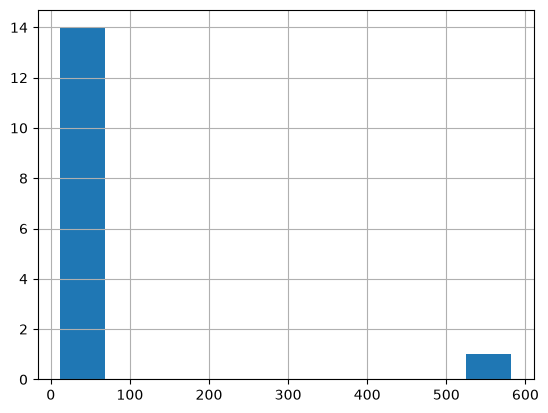

In [15]:
data_clean = data_clean[keep].reset_index(drop=True)
data_clean["est_tokens"].hist(bins=10)
print("长度分布（估算 token）:")
print(data_clean["est_tokens"].describe().round(1).to_string())

## 7. 去重：精确 + 近似

### 精确去重
归一化（去空白、全角转半角、小写）后算哈希，完全相同的丢掉。

### 近似去重
"解释什么是向量数据库" 和 "解释一下什么是向量数据库" 归一化后仍不同，
但语义一样。用 `difflib.SequenceMatcher` 算相似度，超过阈值就认为是重复。
生产环境样本量大时，用 MinHash / SimHash（第 09 节）把 O(n²) 降下来。

In [16]:
def norm_key(text) -> str:
    text = "" if pd.isna(text) else str(text)
    text = unicodedata.normalize("NFKC", text).lower()
    return re.sub(r"\s+", "", text)


data_clean["dedup_key"] = data_clean["prompt"].map(norm_key) + "||" + data_clean["response"].map(norm_key)
data_clean["key_hash"] = data_clean["dedup_key"].map(lambda s: hashlib.md5(s.encode("utf-8")).hexdigest())

exact_dups = data_clean[data_clean["key_hash"].duplicated(keep="first")]
print("精确重复:", len(exact_dups))
exact_dups[["id", "source", "prompt"]]

精确重复: 1


,id,source,prompt
9,alpaca-04,alpaca,解释什么是向量数据库


In [17]:
data_clean = data_clean.drop_duplicates("key_hash", keep="first").reset_index(drop=True)

# 近似重复：两两比较（数据量小，O(n²) 可以接受）
keys = data_clean["dedup_key"].tolist()
near_pairs = []
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        ratio = SequenceMatcher(None, keys[i], keys[j]).ratio()
        if ratio >= 0.9:
            near_pairs.append({"保留": i, "判重": j, "相似度": round(ratio, 3)})

near_pairs = pd.DataFrame(near_pairs)
print("近似重复对:", len(near_pairs))
near_pairs

近似重复对: 1


,保留,判重,相似度
0,6,7,0.978


In [18]:
# 丢弃"被判重"的那些行
if len(near_pairs):
    drop_idx = near_pairs["判重"].tolist()
    print("将丢弃:", data_clean.loc[drop_idx, ["id", "source", "prompt"]].to_dict("records"))
    data_clean = data_clean.drop(index=drop_idx).reset_index(drop=True)

print("去重后:", len(data_clean))

将丢弃: [{'id': 'alpaca-02', 'source': 'alpaca', 'prompt': '解释一下什么是向量数据库'}]
去重后: 13


## 8. 划分训练集 / 验证集

三条硬规则：

1. **可复现**：用哈希分桶，不要用 `random`（每次跑结果不同）；
2. **不泄漏**：同一篇文档/同一个对话产生的样本必须落在同一边；
3. **按来源分层**：每个来源都要同时出现在 train 和 val 里，否则验证集评估不了该来源。
   （样本数 < 2 的来源没法分层，只能整体进训练集，要在报告里标注。）

做法：给每条样本算一个 0~99 的稳定分桶号，再在**每个来源内部**按分桶号排序，前 30% 进验证集。

In [19]:
def bucket_of(text: str, mod: int = 100) -> int:
    return int(hashlib.md5(str(text).encode("utf-8")).hexdigest()[:8], 16) % mod


def val_quota(n: int) -> int:
    """每个来源的验证集配额：少于 2 条不分层，否则至少 1 条、约 30%。"""
    return 0 if n < 2 else max(1, round(n * 0.3))


data_clean["bucket"] = data_clean["id"].map(bucket_of)
data_clean["rank_in_source"] = data_clean.groupby("source")["bucket"].rank(method="first")
data_clean["n_in_source"] = data_clean.groupby("source")["id"].transform("size")
data_clean["n_val"] = data_clean["n_in_source"].map(val_quota)
data_clean["split"] = np.where(data_clean["rank_in_source"] <= data_clean["n_val"], "val", "train")

pd.crosstab(data_clean["source"], data_clean["split"], margins=True, margins_name="合计")

split,train,val,合计
source,,,
alpaca,5,2,7
enterprise,1,0,1
online,3,2,5
合计,9,4,13


## 9. 导出成训练格式

内部统一 schema → 目标格式，一个转换函数就够。
注意 `json.dumps(..., ensure_ascii=False)`，否则中文会变成 `\u4e2d\u6587`（虽然合法，但不可读、体积更大）。

In [20]:
def to_alpaca(row: dict) -> dict:
    return {"instruction": row["prompt"], "input": "", "output": row["response"]}


def to_sharegpt(row: dict) -> dict:
    return {
        "conversations": [
            {"from": "human", "value": row["prompt"]},
            {"from": "gpt", "value": row["response"]},
        ]
    }


def to_messages(row: dict) -> dict:
    return {"messages": row["messages"]}


sample = data_clean.iloc[0].to_dict()
print(json.dumps(to_alpaca(sample), ensure_ascii=False, indent=2))
print(json.dumps(to_sharegpt(sample), ensure_ascii=False, indent=2))

{
  "instruction": "怎么给文档建立向量索引？",
  "input": "",
  "output": "先切分文档，再调用 embedding 接口，最后写入向量库。"
}
{
  "conversations": [
    {
      "from": "human",
      "value": "怎么给文档建立向量索引？"
    },
    {
      "from": "gpt",
      "value": "先切分文档，再调用 embedding 接口，最后写入向量库。"
    }
  ]
}


In [21]:
def write_jsonl(records: list[dict], path: Path) -> None:
    with path.open("w", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")
    print(f"{path.name}: {len(records)} 条")


train_rows = data_clean[data_clean["split"] == "train"].to_dict("records")
val_rows = data_clean[data_clean["split"] == "val"].to_dict("records")

write_jsonl([to_alpaca(r) for r in train_rows], OUT / "sft_train.jsonl")
write_jsonl([to_alpaca(r) for r in val_rows], OUT / "sft_val.jsonl")
write_jsonl([to_messages(r) for r in train_rows], OUT / "sft_train_messages.jsonl")

# 内部统一 schema 存一份 Parquet：便于后续增量更新、按字段筛选
export_cols = ["id", "source", "system", "prompt", "response", "messages", "n_turns", "est_tokens", "split"]
data_clean[export_cols].to_parquet(OUT / "sft_dataset.parquet", index=False)

sft_train.jsonl: 9 条
sft_val.jsonl: 4 条
sft_train_messages.jsonl: 9 条


In [22]:
print((OUT / "sft_train.jsonl").read_text(encoding="utf-8").splitlines()[0])

{"instruction": "怎么给文档建立向量索引？", "input": "", "output": "先切分文档，再调用 embedding 接口，最后写入向量库。"}


## 10. 用 `datasets` 读回来验收

导出之后一定要"回读一遍"，确认字段、条数、编码都对。

In [23]:
import datasets
from datasets import load_dataset

datasets.disable_progress_bars()      # 关掉进度条，输出更干净

ds = load_dataset(
    "json",
    data_files={"train": str(OUT / "sft_train.jsonl"), "validation": str(OUT / "sft_val.jsonl")},
)
print(ds)
print(ds["train"][0])

DatasetDict({
    train: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 9
    })
    validation: Dataset({
        features: ['instruction', 'input', 'output'],
        num_rows: 4
    })
})
{'instruction': '怎么给文档建立向量索引？', 'input': '', 'output': '先切分文档，再调用 embedding 接口，最后写入向量库。'}


## 11. 小练习：从 FAQ JSON 生成样本并合并

`faq_qa.json` 是嵌套结构：`{"faq": [{"category": ..., "qa": [{"q": ..., "a": ...}]}]}`。

任务：

1. 用 `json_normalize(record_path="qa", meta="category")` 展平；
2. 转成内部 schema（`source="faq"`）；
3. 和 `data_clean` 合并，统计各来源条数。

In [24]:
faq = json.loads((RAW_SFT / "faq_qa.json").read_text(encoding="utf-8"))
faq_df = pd.json_normalize(faq["faq"], record_path="qa", meta="category").rename(columns={"q": "question", "a": "answer"})
faq_df["prompt"] = faq_df["question"]
faq_df["response"] = faq_df["answer"]
faq_df[["category", "question", "answer"]]

,category,question,answer
0,售后,收到商品有质量问题怎么办？,签收 7 天内联系客服，提供订单号与照片，质量问题运费由商家承担。
1,售后,支持无理由退货吗？,支持 7 天无理由退货，商品需完好、吊牌未剪。
2,发票,如何开具发票？,下单时填写抬头与税号，或联系客服补开，电子发票 3 个工作日内发送。
3,发票,可以开专票吗？,可以，需要提供公司名称、税号与一般纳税人证明。
4,配送,多久能发货？,现货商品 48 小时内发货，预售商品以商品页说明为准。
5,配送,可以指定送达时间吗？,在订单备注中说明，我们会尽量满足，不保证 100% 达成。


In [25]:
faq_rows = pd.DataFrame({
    "id": "faq-" + pd.Series(range(1, len(faq_df) + 1)).astype(str),
    "source": "faq",
    "system": pd.NA,
    "prompt": faq_df["prompt"],
    "response": faq_df["response"],
    "messages": [
        [{"role": "user", "content": q}, {"role": "assistant", "content": a}]
        for q, a in zip(faq_df["prompt"], faq_df["response"])
    ],
    "model": pd.NA,
    "lang": "zh",
    "n_turns": 2,
    "first_role": "user",
})
faq_rows["est_tokens"] = faq_rows["prompt"].map(estimate_tokens) + faq_rows["response"].map(estimate_tokens)

merged = pd.concat([data_clean[["id", "source", "prompt", "response", "est_tokens"]], faq_rows[["id", "source", "prompt", "response", "est_tokens"]]], ignore_index=True)
merged["source"].value_counts().to_frame("条数")

,条数
source,
alpaca,7
faq,6
online,5
enterprise,1


## 12. 小结与检查清单

**完整链路**

```python
records, bad = read_jsonl(path)              # 容错读取
turns = explode + json_normalize             # 摊平对话
data = 统一成 id/source/prompt/response       # 跨来源对齐
data = 校验 + 脱敏 + 质量过滤 + 去重           # 清洗
data = 按来源分层 + 哈希分桶                   # 划分
data → alpaca / sharegpt / messages          # 导出
```

**交付前自查**

- [ ] 条数能对上：原始 → 校验丢弃 → 过滤丢弃 → 去重丢弃 → 最终，每一步都有数字
- [ ] 没有任何一条的 prompt/response 为空或只有空白
- [ ] 长度分布合理：中位数、P95、最大值都看过，`max_length` 有依据
- [ ] 训练集和验证集**没有**相同 prompt（哈希校验一遍）
- [ ] 没有真实手机号/邮箱/身份证
- [ ] 抽样 20 条人工读一遍：格式对、内容通、没有乱码
- [ ] 导出文件编码是 UTF-8，中文没有变成 `\uXXXX`

**一句话**：数据质量的上限决定模型效果的上限，而数据质量的每一步都应该是**可统计、可复现、可回滚**的。